### Instalação das dependências

Os pacotes abaixo são necessários para construção e exportação do pipeline scikit-learn. Execute esta célula antes de qualquer outra.

In [1]:
!pip install scikit-learn pandas joblib matplotlib -q

# Código 1.1 — Pipeline Reprodutível em Machine Learning

**Objetivo:** Demonstrar como encapsular o pré-processamento e o modelo preditivo em um `Pipeline` do scikit-learn, garantindo reprodutibilidade e eliminando o vazamento de dados (*data leakage*).

### Fluxo do Pipeline

<table style="width: 100%; border-collapse: collapse; text-align: center; font-family: sans-serif; font-size: 13px; margin: 10px 0;">
  <tr style="background-color: #f8fafc;">
    <td style="padding: 6px; border: 1px solid #e2e8f0; font-weight: bold; color: #334155; width: 22%;">Dados Brutos</td>
    <td style="padding: 6px; border: 1px solid #e2e8f0; color: #94a3b8; width: 4%; font-weight: bold;">&rarr;</td>
    <td style="padding: 6px; border: 1px solid #e2e8f0; background-color: #eff6ff; font-weight: bold; color: #1e40af; width: 24%;">SimpleImputer<br><span style="font-size: 11px; font-weight: normal; color: #3b82f6;">(Mediana)</span></td>
    <td style="padding: 6px; border: 1px solid #e2e8f0; color: #94a3b8; width: 4%; font-weight: bold;">&rarr;</td>
    <td style="padding: 6px; border: 1px solid #e2e8f0; background-color: #eff6ff; font-weight: bold; color: #1e40af; width: 24%;">StandardScaler<br><span style="font-size: 11px; font-weight: normal; color: #3b82f6;">(Escala z-score)</span></td>
    <td style="padding: 6px; border: 1px solid #e2e8f0; color: #94a3b8; width: 4%; font-weight: bold;">&rarr;</td>
    <td style="padding: 6px; border: 1px solid #e2e8f0; background-color: #f0fdf4; font-weight: bold; color: #166534; width: 22%;">RandomForest<br><span style="font-size: 11px; font-weight: normal; color: #16a34a;">(Modelo Final)</span></td>
  </tr>
</table>



### Passo 1: Configuração do Ambiente e Geração de Dados Sintéticos

Antes de construir o pipeline, verificamos se o arquivo `dados_industriais.csv` existe localmente. Caso não exista, geramos um dataset sintético de sensores industriais.

In [2]:
from pathlib import Path
import pandas as pd
from sklearn.datasets import make_classification

# Gerar dados sintéticos caso o arquivo não exista
if not Path("dados_industriais.csv").exists():
    X, y = make_classification(
        n_samples=1000,
        n_features=4,
        n_informative=3,
        n_redundant=0,
        random_state=42,
        weights=[0.7, 0.3],
    )
    df = pd.DataFrame(X, columns=["temperatura", "vibracao", "pressao", "rpm"])
    df["falha"] = y
    df.to_csv("dados_industriais.csv", index=False)
    print("Arquivo dados_industriais.csv gerado com sucesso!")
else:
    print("Arquivo dados_industriais.csv encontrado.")

Arquivo dados_industriais.csv gerado com sucesso!


**Entendendo os parâmetros utilizados em `make_classification`:**
- `n_samples=1000`: Quantidade total de linhas (exemplos/observações) geradas no dataset.
- `n_features=4`: Número total de colunas preditoras (variáveis de entrada).
- `n_informative=3`: Número de colunas que realmente possuem poder preditivo em relação à variável resposta.
- `n_redundant=0`: Número de colunas geradas como combinações lineares das colunas informativas.
- `random_state=42`: Semente aleatória para garantir a reprodução exata dos dados gerados.
- `weights=[0.7, 0.3]`: Proporção das classes na variável alvo (70% para a classe normal 0 e 30% para a classe de falha 1).

### Passo 2: Importação das Bibliotecas Necessárias

Importamos as ferramentas do `scikit-learn` para imputer, scaler, modelo, métricas e visualizações gráficos.

In [3]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("dados_industriais.csv")
MODEL_PATH = Path("pipeline_producao_v1.joblib")

### Passo 3: Carga dos Dados e Divisão Treino / Teste (Estratificada)

Carregamos o dataset e realizamos o `train_test_split` com `stratify=y` para garantir a mesma proporção de falhas nos dados de treino e de teste.

In [4]:
# Carregar dataset
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["falha"])
y = df["falha"]

# Divisão estratificada (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Formato dos dados de treino: {X_train.shape}")
print(f"Formato dos dados de teste: {X_test.shape}")

Formato dos dados de treino: (800, 4)
Formato dos dados de teste: (200, 4)


**Ponto de Atenção em Engenharia de ML:**
> Nunca aplique o pré-processamento (como imputação ou escala) no dataset completo antes de separar os dados de treino e teste. Se fizer isso, estatísticas do conjunto de teste (como média ou mediana) irão 'vazar' para o treino, gerando métricas falsamente otimistas.

### Passo 4: Construção do Pipeline de Machine Learning

Encapsulamos a imputação da mediana (`SimpleImputer`), a padronização (`StandardScaler`) e o modelo (`RandomForestClassifier`) em um único objeto `Pipeline`.

In [5]:
# Definição das etapas do pipeline
pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

print("Pipeline configurado com sucesso:")
print(pipeline)

Pipeline configurado com sucesso:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', RandomForestClassifier(n_jobs=-1, random_state=42))])


### Passo 5: Treinamento e Avaliação Visual da Métrica AUC

Treinamos o pipeline completo utilizando `fit` nos dados de treino e geramos o gráfico da curva ROC no conjunto de teste.

AUC no conjunto de teste: 0.9811


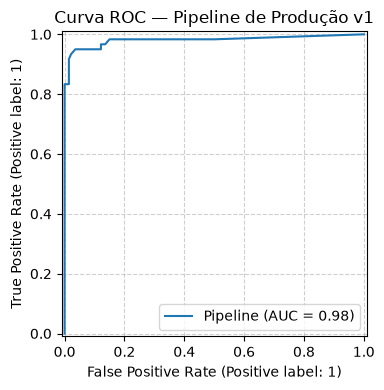

In [6]:
# Treinar pipeline completo
pipeline.fit(X_train, y_train)

# Calcular probabilidade de falha
probabilidades = pipeline.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, probabilidades)

print(f"AUC no conjunto de teste: {auc:.4f}")

# Exibir Curva ROC Visual
fig, ax = plt.subplots(figsize=(6, 4))
RocCurveDisplay.from_estimator(pipeline, X_test, y_test, ax=ax)
plt.title("Curva ROC — Pipeline de Produção v1")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Passo 6: Exportação e Verificação de Integridade

Salvamos o artefato e executamos uma verificação automatizada (`assert`) para confirmar a gravação em disco.

In [7]:
# Salvar o pipeline completo em disco
joblib.dump(pipeline, MODEL_PATH)

# Verificação de Sanidade (Checklist)
assert MODEL_PATH.exists(), "Erro: O arquivo do pipeline não foi criado no disco."
print(f"Verificação concluída: Pipeline salvo com sucesso em '{MODEL_PATH}'")

Verificação concluída: Pipeline salvo com sucesso em 'pipeline_producao_v1.joblib'


---

## Conclusão da Aula — Pipeline Reprodutível

Nesta aula, vimos que **o pipeline é o modelo**. Ao encapsular todas as etapas de imputação e escala junto com o estimador, garantimos que o código rodado em desenvolvimento se comporte de forma **idêntica** no ambiente de produção, prevenindo erros de vazamento de dados (*data leakage*).